# Operating modes: grid search for every model

`model_comparison_lstm.ipynb` ran each model with one hand-picked set of settings. This
notebook searches a grid of settings for every model, picks the best by cross-validation,
and only then scores the winners on the test episodes, once.

| step | what happens |
|---|---|
| 1. Load, clean, split | exactly as in the comparison notebook, so the numbers are comparable |
| 2. Folds | the same 5 folds over the training episodes; every grid point is scored on all 5 |
| 3. Models and grids | each grid contains the current default, so you can see whether tuning helped |
| 4. Search | `GridSearchCV` per model; results are saved to `data/grid_search/` as they finish |
| 5. Read the results | best settings, and which settings are tied with the best |
| 6. Test, once | default and tuned version of each model on the unseen test episodes |
| 7. Save | the tuned settings as `best_params.json`, to paste into the comparison notebook |

**The rule that keeps this honest:** the search only ever sees the training episodes. The
test set is used in step 6 and nowhere else. If you look at the test score and then change
a grid, the test score stops being an honest estimate.

**Run time.** The full grids are about 1,050 model fits. Estimated from the fit times
measured on the 2-core machine the comparison ran on:

| model | full grid | small grid |
|---|---|---|
| HGB | 120 fits, ~50 min | 20 fits, ~7 min |
| Random Forest | 120 fits, ~80 min (wider `max_features` and smaller leaves are slower) | 20 fits, ~10 min |
| Extra Trees | 120 fits, ~15 min | 20 fits, ~3 min |
| Decision tree | 480 fits, ~8 min (run in parallel) | 30 fits, < 1 min |
| Logistic regression | 50 fits, ~3 min | 15 fits, < 1 min |
| k-NN | 100 fits, ~15 min | 15 fits, ~1 min |
| LSTM | 60 fits, ~85 min | 10 fits, ~10 min |
| **total** | **about 4 hours** | **about 30 minutes** |

A recent laptop is usually 2 to 4 times faster. Run `GRID = "small"` first to check that
everything works, then `"full"`. Each model's result is saved when its search finishes; with
`SKIP_DONE = True` a rerun after an interruption picks up where it stopped. To tune only some
models, shorten `TUNE`.

Needs `data/labelled.parquet` from `operating_mode_dataset(2).ipynb`, and PyTorch for the
LSTM (`%pip install torch`; without it the LSTM is skipped).

In [2]:
from pathlib import Path

ROOT = Path(".")             # package folder with labels.csv and data/
DATA = ROOT / "data"
OUT = DATA / "grid_search"   # search results are written here

GRID = "small"                # "small": quick check that everything runs; "full": the real search
TUNE = ["hist_gradient_boosting", "random_forest", "extra_trees", "decision_tree",
        "logistic_regression", "k_nearest_neighbours", "lstm"]    # remove a name to skip it
SKIP_DONE = True             # reuse a model's saved result for this GRID instead of searching again
COMPARE_WITH_DEFAULTS = True # step 6 also fits each model with its default settings

SPLIT = "time"               # "time" or "vessel", as in the comparison notebook
CUTOFF = "2025-07-01"
TEST_VESSEL = "wendover-trader"
GAP_HOURS = 6
N_FOLDS = 5
USE_MISSING_FLAGS = True
RANDOM_STATE = 0
N_JOBS = -1                  # CPU cores, -1 = all
DEVICE = "mps"               # LSTM: "cuda" on an NVIDIA GPU, "mps" on Apple silicon (try it)

In [3]:
import json
import re
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import cohen_kappa_score, f1_score, make_scorer
from sklearn.model_selection import GridSearchCV, ParameterGrid, StratifiedGroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=ConvergenceWarning)   # logistic regression at large C
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

MODES = ["sea_passage", "manoeuvring", "at_anchor", "in_port", "cargo_operations"]
META = ["vessel", "timestamp", "episode", "label_A", "label_B", "mode", "near_boundary", "split"]

INK, INK_2, MUTED, GRID_LINE, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": INK_2, "grid.color": GRID_LINE,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
})


def slug(name):
    return re.sub(r"[^a-z0-9]+", "-", str(name).lower()).strip("-")


def macro_f1_present(y_true, y_pred):
    # Macro F1 over the modes present in y_true (a fold without an anchorage is not scored on at_anchor).
    return f1_score(y_true, y_pred, labels=sorted(set(y_true)), average="macro", zero_division=0)


SCORER = make_scorer(macro_f1_present)

## 1. Load, clean, split

The same steps as the comparison notebook, condensed: rule-based cleaning (clip to the
plausible ranges, fill "never seen moving" with the 72 h cap), then the split by episode.
`train_all` keeps the boundary minutes as context for the LSTM; `train` drops them and is
what the row models learn from and every model is scored on.

In [4]:
df = pd.read_parquet(DATA / "labelled.parquet")
FEATURES = [c for c in df.columns if c not in META]

PLAUSIBLE = {"wind_rel_kn": (0, 70), "sog_kn": (0, None)}
HOURS_CAP = 72


def clean_features(X):
    X = X.copy()
    for col, (lo, hi) in PLAUSIBLE.items():
        X[col] = X[col].clip(lo, hi)
    for col in ("hours_since_moving", "hours_until_moving"):
        X[col] = X[col].fillna(HOURS_CAP)
    return X


df[FEATURES] = clean_features(df[FEATURES])


def load_labels(path, gap_hours=6):
    lab = pd.read_csv(path, parse_dates=["start", "end"])
    lab[["start", "end"]] = lab[["start", "end"]].astype("datetime64[ns]")
    lab["vessel"] = lab["vessel"].map(slug)
    lab["labeller"] = lab["labelled_by"].astype(str).str.split().str[-1]
    lab = lab.sort_values(["vessel", "start"]).reset_index(drop=True)
    reach = lab.groupby("vessel")["end"].transform(lambda s: s.cummax().shift())
    new = reach.isna() | (lab["start"] > reach + pd.Timedelta(hours=gap_hours))
    n = new.astype(int).groupby(lab["vessel"]).cumsum()
    lab["episode"] = lab["vessel"] + "-" + n.astype(str).str.zfill(2)
    return lab


lab = load_labels(ROOT / "labels.csv", GAP_HOURS)
assert set(df["episode"]) <= set(lab["episode"]), "episodes differ from the dataset notebook, check GAP_HOURS"

if SPLIT == "time":
    ep_start = lab.groupby("episode")["start"].min()
    is_test = df["episode"].isin(ep_start.index[ep_start >= pd.Timestamp(CUTOFF)])
elif SPLIT == "vessel":
    is_test = df["vessel"] == slug(TEST_VESSEL)
else:
    raise ValueError(f"SPLIT must be 'time' or 'vessel', not {SPLIT!r}")

train_all = df[~is_test].reset_index(drop=True)
train = train_all[~train_all["near_boundary"]].reset_index(drop=True)
test = df[is_test].reset_index(drop=True)
assert not set(train_all["episode"]) & set(test["episode"]), "an episode is on both sides"

X_train, y_train, groups = train[FEATURES], train["mode"], train["episode"]
X_test, y_test = test[FEATURES], test["mode"]
print(f"train: {len(train):,} rows ({len(train_all):,} with boundary minutes), "
      f"{train['episode'].nunique()} episodes;  test: {len(test):,} rows, {test['episode'].nunique()} episodes")

train: 90,862 rows (91,905 with boundary minutes), 13 episodes;  test: 70,565 rows, 10 episodes


In [5]:
# The ceiling, labeller A against labeller B, for the per-mode table in step 6
def minute_labels(lab, who):
    parts = [pd.DataFrame({"vessel": r.vessel, "mode": r.mode,
                           "timestamp": pd.date_range(r.start, r.end, freq="min", inclusive="left")})
             for r in lab[lab["labeller"] == who].itertuples()]
    return pd.concat(parts, ignore_index=True)


both = minute_labels(lab, "A").merge(minute_labels(lab, "B"), on=["vessel", "timestamp"], suffixes=("_A", "_B"))
rater_f1 = pd.Series(f1_score(both["mode_A"], both["mode_B"], labels=MODES, average=None),
                     index=MODES, name="rater agreement")
rater_f1.round(3).to_frame().T

,sea_passage,manoeuvring,at_anchor,in_port,cargo_operations
rater agreement,0.999,0.944,0.557,0.692,0.94


## 2. The folds

Every grid point of every model is scored on the same 5 folds, so scores can be compared
across models. Whole episodes are held out, never single minutes (the comparison notebook's
step 8 showed how much a row split inflates the score).

Two versions of the same folds: row positions in `train` for the scikit-learn models, and
row positions in `train_all` for the LSTM, which needs the held-out episodes whole. Both hold
out the same episodes and both are scored on the same minutes (the non-boundary ones).

In [6]:
cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
folds = list(cv.split(X_train, y_train, groups))
fold_episodes = [set(groups.iloc[te]) for _, te in folds]

in_fold = [train_all["episode"].isin(held).to_numpy() for held in fold_episodes]
lstm_folds = [(np.flatnonzero(~held), np.flatnonzero(held)) for held in in_fold]

pd.DataFrame([{"fold": i, "held_out_episodes": ", ".join(sorted(e.replace("-trader", "") for e in held)),
               **(y_train.iloc[te].value_counts() / 60).reindex(MODES).fillna(0).round(1).to_dict()}
              for i, ((_, te), held) in enumerate(zip(folds, fold_episodes))]).set_index("fold")

,held_out_episodes,sea_passage,manoeuvring,at_anchor,in_port,cargo_operations
fold,,,,,,
0,"brayton-06, wendover-05",201.8,7.2,16.6,33.5,61.5
1,"brayton-02, brayton-03, wendover-04",202.1,8.7,0.0,25.9,83.2
2,"wendover-01, wendover-03, wendover-06",176.0,12.2,17.8,33.6,133.8
3,"brayton-04, brayton-07",122.1,3.7,34.5,24.0,69.2
4,"brayton-01, brayton-05, wendover-02",109.2,7.8,7.8,21.6,100.5


## 3. Models and grids

Every scikit-learn model is a `Pipeline` with named steps, so a grid key reads as
`step__setting`: `model__min_samples_leaf` is the forest's `min_samples_leaf`. Fill and scale
steps are inside the pipeline, so they are re-fitted on the training part of every fold.

What is searched, and why those settings:

| model | searched | why these |
|---|---|---|
| HGB | learning rate, number of trees, leaves per tree, minimum minutes per leaf | rate and trees trade off; leaves and leaf size control how fine each tree cuts |
| Random Forest / Extra Trees | features tried per split, minimum minutes per leaf, class weights | leaf size is the main brake on overfitting near-duplicate minutes |
| Decision tree | depth, minimum minutes per leaf, split criterion, class weights | a single tree lives or dies by how deep it may grow |
| Logistic regression | regularisation `C`, class weights | the only real knob of a linear model |
| k-NN | number of neighbours, vote weighting, distance (`p=1` city-block, `p=2` straight line) | |
| LSTM | window length, memory size, dropout | how much context it sees, how much it can hold, how hard it is held back from memorising the 13 training episodes (in the comparison its training loss went close to zero) |

**Not searched on purpose:** the number of trees in the forests. More trees never makes a
forest worse, only slower; 300 is plenty here. Searching it wastes time.

Each grid contains the default from the comparison notebook, marked in step 5. To also test
the missing-value flags, add `"prep__add_indicator": [True, False]` to a grid (it doubles it).

In [7]:
def pipeline(model, scale=False, impute=True):
    steps = [("prep", SimpleImputer(strategy="median", add_indicator=USE_MISSING_FLAGS))] if impute else []
    steps += [("scale", StandardScaler())] if scale else []
    return Pipeline(steps + [("model", model)])


BASE = {
    # HGB handles NaN itself; without missing flags it gets the median fill like the others
    "hist_gradient_boosting": pipeline(HistGradientBoostingClassifier(
        class_weight="balanced", early_stopping=False, max_iter=200, learning_rate=0.1,
        random_state=RANDOM_STATE), impute=not USE_MISSING_FLAGS),
    "random_forest": pipeline(RandomForestClassifier(
        n_estimators=300, min_samples_leaf=3, max_features="sqrt", class_weight="balanced_subsample",
        n_jobs=N_JOBS, random_state=RANDOM_STATE)),
    "extra_trees": pipeline(ExtraTreesClassifier(
        n_estimators=300, min_samples_leaf=3, max_features="sqrt", class_weight="balanced_subsample",
        n_jobs=N_JOBS, random_state=RANDOM_STATE)),
    "decision_tree": pipeline(DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=20, class_weight="balanced", random_state=RANDOM_STATE)),
    "logistic_regression": pipeline(LogisticRegression(
        C=1.0, max_iter=3000, class_weight="balanced"), scale=True),
    "k_nearest_neighbours": pipeline(KNeighborsClassifier(
        n_neighbors=25, weights="distance", n_jobs=N_JOBS), scale=True),
}

GRIDS = {
    "full": {
        "hist_gradient_boosting": {"model__learning_rate": [0.05, 0.1], "model__max_iter": [200, 400],
                                   "model__max_leaf_nodes": [15, 31, 63], "model__min_samples_leaf": [20, 100]},
        "random_forest": {"model__max_features": ["sqrt", 0.3, 0.5], "model__min_samples_leaf": [1, 3, 10, 30],
                          "model__class_weight": ["balanced_subsample", None]},
        "extra_trees": {"model__max_features": ["sqrt", 0.5, 1.0], "model__min_samples_leaf": [1, 3, 10, 30],
                        "model__class_weight": ["balanced_subsample", None]},
        "decision_tree": {"model__max_depth": [4, 6, 8, 12, 16, None], "model__min_samples_leaf": [1, 20, 100, 500],
                          "model__criterion": ["gini", "entropy"], "model__class_weight": ["balanced", None]},
        "logistic_regression": {"model__C": [0.01, 0.1, 1.0, 10.0, 100.0],
                                "model__class_weight": ["balanced", None]},
        "k_nearest_neighbours": {"model__n_neighbors": [5, 15, 25, 50, 100], "model__weights": ["uniform", "distance"],
                                 "model__p": [1, 2]},
        "lstm": {"seq_len": [120, 240, 480], "hidden": [48, 96], "dropout": [0.2, 0.4]},
    },
    "small": {
        "hist_gradient_boosting": {"model__max_iter": [100, 200], "model__max_leaf_nodes": [15, 31]},
        "random_forest": {"model__max_features": ["sqrt", 0.5], "model__min_samples_leaf": [3, 30]},
        "extra_trees": {"model__max_features": ["sqrt", 0.5], "model__min_samples_leaf": [3, 30]},
        "decision_tree": {"model__max_depth": [6, 8, 12], "model__min_samples_leaf": [20, 100]},
        "logistic_regression": {"model__C": [0.1, 1.0, 10.0]},
        "k_nearest_neighbours": {"model__n_neighbors": [10, 25, 50]},
        "lstm": {"seq_len": [240, 480]},
    },
}

# Models that use one core per fit are searched in parallel; the others already use every core
SEARCH_JOBS = {"decision_tree": N_JOBS, "logistic_regression": N_JOBS}

### The LSTM, as a scikit-learn estimator

The same network as in the comparison notebook. It now inherits from scikit-learn's
`BaseEstimator`, so `GridSearchCV` can copy it and set its parameters like any other model.
It is given `train_all` (all columns) and the `lstm_folds`, and scored only on the
non-boundary minutes of each held-out fold, the same minutes the row models are scored on.

In [8]:
try:
    import torch
    from torch import nn
    from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
    HAVE_TORCH = True
except ImportError:
    HAVE_TORCH = False

if HAVE_TORCH:
    class BiLSTMNet(nn.Module):
        def __init__(self, n_in, n_out, hidden, layers, dropout):
            super().__init__()
            self.lstm = nn.LSTM(n_in, hidden, num_layers=layers, batch_first=True, bidirectional=True,
                                dropout=dropout if layers > 1 else 0.0)
            self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(2 * hidden, n_out))

        def forward(self, x, lengths):
            packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
            out, _ = self.lstm(packed)
            out, _ = pad_packed_sequence(out, batch_first=True, total_length=x.shape[1])
            return self.head(out)


class LSTMClassifier(ClassifierMixin, BaseEstimator):
    # Bidirectional LSTM over each vessel's minutes, one mode per minute. X is a table with
    # vessel, timestamp, near_boundary and FEATURES; y the mode per row (or X["mode"]).

    def __init__(self, seq_len=240, hidden=48, layers=1, dropout=0.2, epochs=12, batch_size=32, lr=2e-3,
                 max_gap_min=5, missing_flags=True, device="cpu", random_state=0):
        self.seq_len = seq_len
        self.hidden = hidden
        self.layers = layers
        self.dropout = dropout
        self.epochs = epochs
        self.batch_size = batch_size
        self.lr = lr
        self.max_gap_min = max_gap_min
        self.missing_flags = missing_flags
        self.device = device
        self.random_state = random_state

    def _segments(self, p):
        order = p.sort_values(["vessel", "timestamp"]).index.to_numpy()
        v, t = p["vessel"].to_numpy()[order], p["timestamp"].to_numpy()[order]
        new = np.r_[True, (v[1:] != v[:-1]) | (np.diff(t) > np.timedelta64(self.max_gap_min, "m"))]
        starts = np.flatnonzero(new)
        return [order[s:e] for s, e in zip(starts, np.r_[starts[1:], len(order)])]

    def _windows(self, segs, stride):
        wins = []
        for k, s in enumerate(segs):
            n = len(s)
            if n <= self.seq_len:
                wins.append((k, 0, n))
                continue
            starts = list(range(0, n - self.seq_len + 1, stride))
            if starts[-1] != n - self.seq_len:
                starts.append(n - self.seq_len)
            wins += [(k, a, a + self.seq_len) for a in starts]
        return wins

    def _batch(self, wins, segs, X, y=None, w=None):
        L = max(e - a for _, a, e in wins)
        xb = np.zeros((len(wins), L, X.shape[1]), np.float32)
        yb = np.zeros((len(wins), L), np.int64)
        wb = np.zeros((len(wins), L), np.float32)
        for i, (k, a, e) in enumerate(wins):
            idx = segs[k][a:e]
            xb[i, :e - a] = X[idx]
            if y is not None:
                yb[i, :e - a], wb[i, :e - a] = y[idx], w[idx]
        lengths = torch.tensor([e - a for _, a, e in wins])
        to = lambda a: torch.from_numpy(a).to(self.device)
        return to(xb), to(yb), to(wb), lengths

    def fit(self, X, y=None):
        torch.manual_seed(self.random_state)
        rng = np.random.default_rng(self.random_state)
        p = X.reset_index(drop=True)
        modes = p["mode"] if y is None else pd.Series(np.asarray(y, dtype=object))
        trusted = ~p["near_boundary"].to_numpy(dtype=bool)
        self.classes_ = np.array(MODES, dtype=object)

        self.prep_ = make_pipeline(SimpleImputer(strategy="median", add_indicator=self.missing_flags),
                                   StandardScaler()).fit(p.loc[trusted, FEATURES])
        Xs = self.prep_.transform(p[FEATURES]).astype(np.float32)
        yi = modes.map({m: i for i, m in enumerate(MODES)}).to_numpy(dtype=np.int64)
        counts = np.bincount(yi[trusted], minlength=len(MODES))
        class_w = np.where(counts > 0, counts.sum() / (len(MODES) * np.maximum(counts, 1)), 0.0)
        w = (class_w[yi] * trusted).astype(np.float32)

        segs = self._segments(p)
        wins = self._windows(segs, stride=max(1, self.seq_len // 2))
        net = BiLSTMNet(Xs.shape[1], len(MODES), self.hidden, self.layers, self.dropout).to(self.device)
        opt = torch.optim.Adam(net.parameters(), lr=self.lr)
        for epoch in range(self.epochs):
            net.train()
            order = rng.permutation(len(wins))
            for b in range(0, len(order), self.batch_size):
                xb, yb, wb, lengths = self._batch([wins[i] for i in order[b:b + self.batch_size]], segs, Xs, yi, w)
                ce = nn.functional.cross_entropy(net(xb, lengths).reshape(-1, len(MODES)), yb.reshape(-1),
                                                 reduction="none")
                loss = (ce * wb.reshape(-1)).sum() / wb.sum().clamp(min=1e-8)
                opt.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(net.parameters(), 1.0)
                opt.step()
        self.net_ = net.eval()
        return self

    def predict_proba(self, X):
        p = X.reset_index(drop=True)
        Xs = self.prep_.transform(p[FEATURES]).astype(np.float32)
        segs = self._segments(p)
        wins = self._windows(segs, stride=max(1, self.seq_len // 2))
        prob, seen = np.zeros((len(p), len(MODES))), np.zeros(len(p))
        with torch.no_grad():
            for b in range(0, len(wins), 128):
                batch = wins[b:b + 128]
                xb, _, _, lengths = self._batch(batch, segs, Xs)
                pr = torch.softmax(self.net_(xb, lengths), dim=-1).cpu().numpy()
                for i, (k, a, e) in enumerate(batch):
                    prob[segs[k][a:e]] += pr[i, :e - a]
                    seen[segs[k][a:e]] += 1
        return prob / seen[:, None]

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


def lstm_scorer(estimator, X, y):
    # Score only the non-boundary minutes, the same ones the row models are scored on.
    keep = ~X["near_boundary"].to_numpy(dtype=bool)
    return macro_f1_present(np.asarray(y, dtype=object)[keep], estimator.predict(X)[keep])


if HAVE_TORCH:
    BASE["lstm"] = LSTMClassifier(missing_flags=USE_MISSING_FLAGS, device=DEVICE, random_state=RANDOM_STATE)
else:
    print("PyTorch is not installed, so the LSTM is skipped. In a notebook cell:  %pip install torch")

In [9]:
grids = GRIDS[GRID]
todo = [m for m in TUNE if m in BASE]
plan = pd.DataFrame({
    "grid_points": [len(ParameterGrid(grids[m])) for m in todo],
    "fits": [len(ParameterGrid(grids[m])) * N_FOLDS for m in todo],
    "already_done": [(OUT / f"{m}_{GRID}.json").exists() for m in todo],
}, index=todo)
print(f"GRID = {GRID!r}: {plan['fits'].sum():,} fits in total, "
      f"{plan.loc[~plan['already_done'], 'fits'].sum():,} still to run")
plan

GRID = 'small': 130 fits in total, 130 still to run


,grid_points,fits,already_done
hist_gradient_boosting,4,20,False
random_forest,4,20,False
extra_trees,4,20,False
decision_tree,6,30,False
logistic_regression,3,15,False
k_nearest_neighbours,3,15,False
lstm,2,10,False


## 4. Search

One `GridSearchCV` per model. `refit=False`: the search only scores, the final fit on all
training episodes happens in step 6, where the default and the tuned version are treated
exactly alike. `error_score="raise"` stops on the first error instead of quietly scoring 0.

After each model, two files go to `data/grid_search/`: `<model>_<GRID>.csv` with every grid
point's fold scores and `<model>_<GRID>.json` with the best settings. Interrupt the kernel any
time; with `SKIP_DONE = True` the next run skips the models that are done.

In [10]:
OUT.mkdir(parents=True, exist_ok=True)


def default_params(name):
    # The default's value for every setting in this model's grid.
    return {k: BASE[name].get_params()[k] for k in grids[name]}


for name in todo:
    json_path, csv_path = OUT / f"{name}_{GRID}.json", OUT / f"{name}_{GRID}.csv"
    if SKIP_DONE and json_path.exists():
        print(f"{name:<24} done before, loaded from {json_path.name}")
        continue

    if name == "lstm":
        X, y, splits, scoring, jobs = train_all, train_all["mode"], lstm_folds, lstm_scorer, 1
    else:
        X, y, splits, scoring, jobs = X_train, y_train, folds, SCORER, SEARCH_JOBS.get(name, 1)

    n_fits = len(ParameterGrid(grids[name])) * N_FOLDS
    print(f"{name:<24} {n_fits} fits ...", flush=True)
    t0 = time.perf_counter()
    search = GridSearchCV(BASE[name], grids[name], scoring=scoring, cv=splits, n_jobs=jobs,
                          refit=False, error_score="raise", verbose=0)
    search.fit(X, y)
    minutes = (time.perf_counter() - t0) / 60

    res = pd.DataFrame(search.cv_results_)
    res["params_json"] = [json.dumps(p, sort_keys=True) for p in res["params"]]
    res["is_default"] = res["params_json"] == json.dumps(default_params(name), sort_keys=True)
    res.drop(columns="params").to_csv(csv_path, index=False)
    json.dump({"model": name, "grid": GRID, "best_params": search.best_params_,
               "best_cv_macro_f1": float(search.best_score_),
               "default_cv_macro_f1": float(res.loc[res["is_default"], "mean_test_score"].iloc[0])
               if res["is_default"].any() else None,
               "minutes": round(minutes, 1)}, open(json_path, "w"), indent=2)
    print(f"{'':<24} best {search.best_score_:.4f} with {search.best_params_}   ({minutes:.1f} min)", flush=True)

hist_gradient_boosting   20 fits ...
                         best 0.9883 with {'model__max_iter': 200, 'model__max_leaf_nodes': 15}   (2.7 min)
random_forest            20 fits ...
                         best 0.9880 with {'model__max_features': 'sqrt', 'model__min_samples_leaf': 3}   (2.3 min)
extra_trees              20 fits ...
                         best 0.9864 with {'model__max_features': 0.5, 'model__min_samples_leaf': 3}   (0.4 min)
decision_tree            30 fits ...
                         best 0.9654 with {'model__max_depth': 8, 'model__min_samples_leaf': 20}   (0.1 min)
logistic_regression      15 fits ...
                         best 0.9659 with {'model__C': 0.1}   (0.0 min)
k_nearest_neighbours     15 fits ...
                         best 0.9630 with {'model__n_neighbors': 50}   (0.2 min)
lstm                     10 fits ...
                         best 0.9731 with {'seq_len': 240}   (5.5 min)


## 5. Read the results

`std` is the spread of the score over the 5 folds. With 5 folds, two settings whose means
differ by less than that are **tied**: the data cannot tell them apart, and picking the top
one is partly picking noise. Among tied settings, the simpler or faster one (larger leaves,
fewer trees, shorter windows) is usually the better bet for new ships.

In [11]:
done = [m for m in todo if (OUT / f"{m}_{GRID}.json").exists()]
best = {m: json.load(open(OUT / f"{m}_{GRID}.json")) for m in done}

summary = pd.DataFrame({
    "default_cv": [best[m]["default_cv_macro_f1"] for m in done],
    "best_cv": [best[m]["best_cv_macro_f1"] for m in done],
    "best_params": [", ".join(f"{k.replace('model__', '')}={v}" for k, v in best[m]["best_params"].items())
                    for m in done],
    "search_min": [best[m]["minutes"] for m in done],
}, index=done)
summary.insert(2, "gain", summary["best_cv"] - summary["default_cv"])
summary.sort_values("best_cv", ascending=False).round(4)

,default_cv,best_cv,gain,best_params,search_min
hist_gradient_boosting,0.9856,0.9883,0.0027,"max_iter=200, max_leaf_nodes=15",2.7
random_forest,0.9880,0.9880,0.0000,"max_features=sqrt, min_samples_leaf=3",2.3
extra_trees,0.9850,0.9864,0.0015,"max_features=0.5, min_samples_leaf=3",0.4
lstm,0.9731,0.9731,0.0000,seq_len=240,5.5
logistic_regression,0.9584,0.9659,0.0075,C=0.1,0.0
decision_tree,0.9654,0.9654,0.0000,"max_depth=8, min_samples_leaf=20",0.1
k_nearest_neighbours,0.9624,0.9630,0.0007,n_neighbors=50,0.2


In [12]:
def top_configs(name, n=10):
    res = pd.read_csv(OUT / f"{name}_{GRID}.csv")
    params = [c for c in res.columns if c.startswith("param_")]
    folds_cols = [c for c in res.columns if re.fullmatch(r"split\d+_test_score", c)]
    t = res.sort_values("rank_test_score")[params + ["mean_test_score", "std_test_score", "mean_fit_time", "is_default"]]
    top = t.iloc[0]
    t["tied_with_best"] = t["mean_test_score"] >= top["mean_test_score"] - top["std_test_score"]
    t = t.rename(columns=lambda c: c.replace("param_model__", "").replace("param_", ""))
    print(f"{name}: {len(res)} settings, {int(t['tied_with_best'].sum())} tied with the best "
          f"(within one fold-std, {top['std_test_score']:.4f}); default ranked "
          f"{int(res.loc[res['is_default'], 'rank_test_score'].iloc[0]) if res['is_default'].any() else '-'}")
    return t.head(n).round(4)


for name in done:
    display(top_configs(name))

hist_gradient_boosting: 4 settings, 4 tied with the best (within one fold-std, 0.0083); default ranked 3


,max_iter,max_leaf_nodes,mean_test_score,std_test_score,mean_fit_time,is_default,tied_with_best
2,200,15,0.9883,0.0083,8.0104,False,True
0,100,15,0.9881,0.0083,7.2905,False,True
3,200,31,0.9856,0.0075,9.0205,True,True
1,100,31,0.9855,0.0074,8.0830,False,True


random_forest: 4 settings, 2 tied with the best (within one fold-std, 0.0081); default ranked 1


,max_features,min_samples_leaf,mean_test_score,std_test_score,mean_fit_time,is_default,tied_with_best
0,sqrt,3,0.9880,0.0081,3.6695,True,True
1,sqrt,30,0.9868,0.0087,3.4786,False,True
3,0.5,30,0.9752,0.0147,9.5865,False,False
2,0.5,3,0.9745,0.0187,10.2780,False,False


extra_trees: 4 settings, 4 tied with the best (within one fold-std, 0.0076); default ranked 3


,max_features,min_samples_leaf,mean_test_score,std_test_score,mean_fit_time,is_default,tied_with_best
2,0.5,3,0.9864,0.0076,1.5287,False,True
3,0.5,30,0.9854,0.0089,1.4352,False,True
0,sqrt,3,0.9850,0.0081,0.9559,True,True
1,sqrt,30,0.9824,0.0098,0.9308,False,True


... (4 outputs left out)

k_nearest_neighbours: 3 settings, 3 tied with the best (within one fold-std, 0.0333); default ranked 2


,n_neighbors,mean_test_score,std_test_score,mean_fit_time,is_default,tied_with_best
2,50,0.9630,0.0333,0.2541,False,True
1,25,0.9624,0.0344,0.2524,True,True
0,10,0.9606,0.0371,0.2632,False,True


lstm: 2 settings, 2 tied with the best (within one fold-std, 0.0278); default ranked 1


,seq_len,mean_test_score,std_test_score,mean_fit_time,is_default,tied_with_best
0,240,0.9731,0.0278,31.7807,True,True
1,480,0.9652,0.0400,33.7550,False,True


To see how one setting moves the score, average over the others, for example:

```python
res = pd.read_csv(OUT / f"random_forest_{GRID}.csv")
res.pivot_table(index="param_model__min_samples_leaf", columns="param_model__max_features",
                values="mean_test_score").round(4)
```

## 6. Test, once: default against tuned

Each model is fitted on all training episodes twice, once with the defaults and once with the
best grid point, and both are scored on the test episodes. This is the only place the test set
is used.

How to read it: if the tuned version is better in cross-validation but not on test, the gain
was noise (or specific to the training episodes). Expect the tuned scores in step 5 to be a
little optimistic: the best of many grid points is chosen on the same folds that score it.

In [13]:
def fit_and_predict(name, params):
    est = clone(BASE[name]).set_params(**params)
    t0 = time.perf_counter()
    if name == "lstm":
        est.fit(train_all)                  # boundary minutes as context, not as targets
        pred = est.predict(test)
    else:
        est.fit(X_train, y_train)
        pred = est.predict(X_test)
    return pred, time.perf_counter() - t0


test_pred, rows = {}, []
for name in done:
    versions = [("tuned", best[name]["best_params"])]
    if COMPARE_WITH_DEFAULTS:
        versions.insert(0, ("default", {}))
    for version, params in versions:
        pred, secs = fit_and_predict(name, params)
        test_pred[(name, version)] = pred
        rows.append({"model": name, "version": version, "test_macro_f1": macro_f1_present(y_test, pred),
                     "test_kappa": cohen_kappa_score(y_test, pred),
                     **dict(zip(MODES, f1_score(y_test, pred, labels=MODES, average=None, zero_division=0))),
                     "seconds": secs})
        print(f"{name:<24} {version:<8} test macro F1 {rows[-1]['test_macro_f1']:.4f}   ({secs:.0f} s)", flush=True)

test_scores = pd.DataFrame(rows).set_index(["model", "version"])
test_scores.round(4)

hist_gradient_boosting   default  test macro F1 0.9375   (11 s)
hist_gradient_boosting   tuned    test macro F1 0.9494   (10 s)
random_forest            default  test macro F1 0.9557   (5 s)
random_forest            tuned    test macro F1 0.9557   (5 s)
extra_trees              default  test macro F1 0.9537   (1 s)
extra_trees              tuned    test macro F1 0.9561   (2 s)
decision_tree            default  test macro F1 0.8630   (1 s)
decision_tree            tuned    test macro F1 0.8630   (1 s)
logistic_regression      default  test macro F1 0.9328   (1 s)
logistic_regression      tuned    test macro F1 0.9377   (1 s)
k_nearest_neighbours     default  test macro F1 0.9442   (3 s)
k_nearest_neighbours     tuned    test macro F1 0.9450   (3 s)
lstm                     default  test macro F1 0.9270   (40 s)
lstm                     tuned    test macro F1 0.9270   (40 s)


test_macro_f1  test_kappa  sea_passage  manoeuvring  at_anchor  in_port  cargo_operations  seconds
model                  version                                                                                                    
hist_gradient_boosting default         0.9375      0.9629       0.9986       0.9530     0.9786   0.7842            0.9730  11.3057
                       tuned           0.9494      0.9684       0.9987       0.9527     0.9791   0.8393            0.9771   9.8353
random_forest          default         0.9557      0.9685       0.9990       0.9583     0.9968   0.8493            0.9753   4.9978
                       tuned           0.9557      0.9685       0.9990       0.9583     0.9968   0.8493            0.9753   4.9172
extra_trees            default         0.9537      0.9675       0.9988       0.9565     0.9945   0.8440            0.9748   1.3717
                       tuned           0.9561      0.9689       0.9989       0.9571     0.9960   0.8525            0.9758   2.1331
decision_tree          default         0.8630      0.9248       0.9820       0.9381     0.6075   0.8167            0.9706   1.3968
                       tuned           0.8630      0.9248       0.9820       0.9381     0.6075   0.8167            0.9706   1.3783
logistic_regression    default         0.9328      0.9571       0.9982       0.9527     0.9478   0.7968            0.9685   1.0906
                       tuned           0.9377      0.9592       0.9985       0.9551     0.9579   0.8073            0.9695   0.9848
k_nearest_neighbours   default         0.9442      0.9594       0.9987       0.9539     0.9944   0.8064            0.9676   2.8700
                       tuned           0.9450      0.9625       0.9983       0.9408     0.9897   0.8248            0.9716   2.9827
lstm                   default         0.9270      0.9373       0.9987       0.9626     0.9949   0.7333            0.9453  40.0260
                       tuned           0.9270      0.9373       0.9987       0.9626     0.9949   0.7333            0.9453  40.3142

In [14]:
final = test_scores.xs("tuned", level="version")[["test_macro_f1"] + MODES].join(summary[["default_cv", "best_cv"]])
if COMPARE_WITH_DEFAULTS:
    final.insert(1, "test_default", test_scores.xs("default", level="version")["test_macro_f1"])
final = final.sort_values("test_macro_f1", ascending=False)
ceiling = pd.DataFrame([rater_f1.rename("rater agreement (ceiling)")])
display(pd.concat([final, ceiling]).round(4))

,test_macro_f1,test_default,sea_passage,manoeuvring,at_anchor,in_port,cargo_operations,default_cv,best_cv
extra_trees,0.9561,0.9537,0.9989,0.9571,0.9960,0.8525,0.9758,0.9850,0.9864
random_forest,0.9557,0.9557,0.9990,0.9583,0.9968,0.8493,0.9753,0.9880,0.9880
hist_gradient_boosting,0.9494,0.9375,0.9987,0.9527,0.9791,0.8393,0.9771,0.9856,0.9883
k_nearest_neighbours,0.9450,0.9442,0.9983,0.9408,0.9897,0.8248,0.9716,0.9624,0.9630
logistic_regression,0.9377,0.9328,0.9985,0.9551,0.9579,0.8073,0.9695,0.9584,0.9659
lstm,0.9270,0.9270,0.9987,0.9626,0.9949,0.7333,0.9453,0.9731,0.9731
decision_tree,0.8630,0.8630,0.9820,0.9381,0.6075,0.8167,0.9706,0.9654,0.9654
rater agreement (ceiling),NaN,NaN,0.9988,0.9435,0.5570,0.6925,0.9396,NaN,NaN


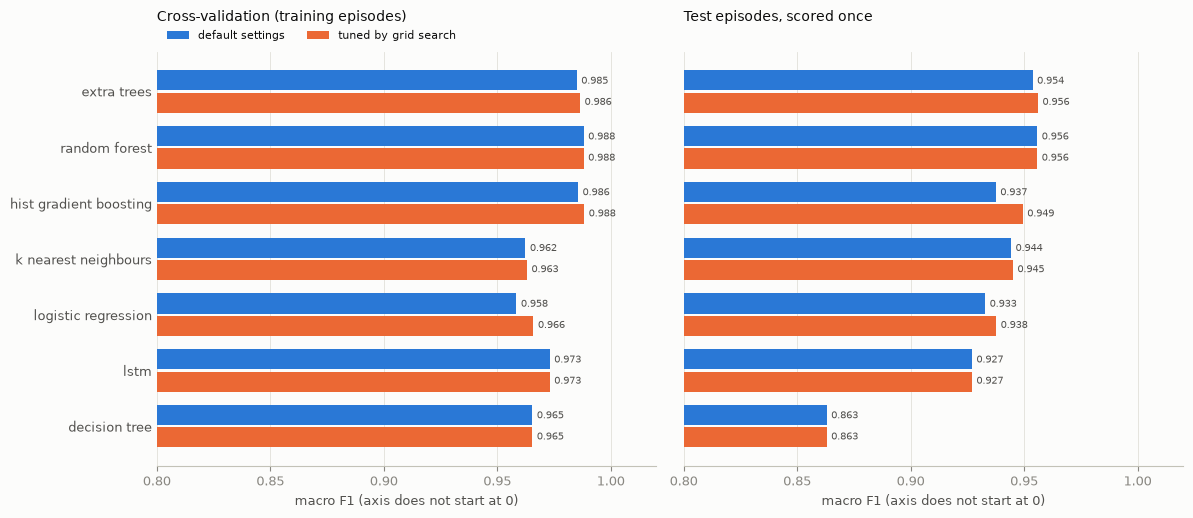

In [15]:
order = final.sort_values("test_macro_f1").index
y = np.arange(len(order))
fig, axes = plt.subplots(1, 2, figsize=(12, 0.55 * len(order) + 1.4), sharey=True)
panels = [(axes[0], "default_cv", "best_cv", "Cross-validation (training episodes)")]
if COMPARE_WITH_DEFAULTS:
    panels.append((axes[1], "test_default", "test_macro_f1", "Test episodes, scored once"))
lo = np.floor((final[[c for _, a, b, _ in panels for c in (a, b)]].min().min() - 0.03) * 20) / 20
for ax, before, after, title in panels:
    h = 0.38
    ax.barh(y + h / 2 + 0.01, final.loc[order, before], height=h - 0.02, color=BLUE, label="default settings")
    ax.barh(y - h / 2 - 0.01, final.loc[order, after], height=h - 0.02, color=ORANGE, label="tuned by grid search")
    for yi, name in zip(y, order):
        for off, col in [(h / 2, before), (-h / 2, after)]:
            ax.text(final.loc[name, col] + 0.002, yi + off, f"{final.loc[name, col]:.3f}",
                    va="center", fontsize=7.5, color=INK_2)
    ax.set_xlim(max(0, lo), 1.02)
    ax.set_xticks(np.arange(max(0, lo), 1.0001, 0.05 if lo < 0.85 else 0.025))
    ax.grid(axis="x", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.set_xlabel("macro F1 (axis does not start at 0)")
    ax.set_title(title, loc="left", fontsize=10, pad=22)
axes[0].set_yticks(y, [n.replace("_", " ") for n in order])
axes[0].legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=8)
if not COMPARE_WITH_DEFAULTS:
    axes[1].set_visible(False)
plt.tight_layout()
plt.show()

## 7. Save the tuned settings

`data/grid_search/best_params.json` holds the winner per model. To use them in
`model_comparison_lstm.ipynb`, after its step 5 cell:

```python
import json
best = json.load(open("data/grid_search/best_params.json"))
for name, params in best.items():
    if name == "lstm":
        for k, v in params.items():
            if "lstm" in MODELS:
                setattr(MODELS["lstm"], k, v)
        continue
    est = ESTIMATORS[name]
    model = est[-1] if hasattr(est, "steps") else est      # the classifier at the end of the pipeline
    model.set_params(**{k.removeprefix("model__"): v for k, v in params.items() if k.startswith("model__")})
```

The comparison notebook builds its pipelines with `make_pipeline`, whose step names differ
(`randomforestclassifier__...`), so the snippet strips `model__` and sets each value on the
classifier at the end of the pipeline. A setting you added on another step (such as
`prep__add_indicator`) has to be carried over by hand.

In [16]:
best_params = {m: best[m]["best_params"] for m in done}
json.dump(best_params, open(OUT / "best_params.json", "w"), indent=2)

for m, params in best_params.items():
    print(f"{m}:")
    for k, v in params.items():
        print(f"    {k.replace('model__', ''):<22} {v!r}")
print(f"\nwritten to {OUT / 'best_params.json'}")

hist_gradient_boosting:
    max_iter               200
    max_leaf_nodes         15
random_forest:
    max_features           'sqrt'
    min_samples_leaf       3
extra_trees:
    max_features           0.5
    min_samples_leaf       3
decision_tree:
    max_depth              8
    min_samples_leaf       20
logistic_regression:
    C                      0.1
k_nearest_neighbours:
    n_neighbors            50
lstm:
    seq_len                240

written to data/grid_search/best_params.json
